# 20c. 최종 모델 PR-AUC · PR 곡선

`20a_final_train.ipynb`로 저장한 모델을 불러와 평가 (학습 다시 안 함)

**PR-AUC 두 가지 계산법**
| 지표 | 계산 | 특징 |
|---|---|---|
| **AP** (= 계단식 PR-AUC) | 각 불량을 만날 때의 정밀도 평균 | sklearn·논문 표준, 주 지표 |
| **PR-AUC(사다리꼴)** | PR 곡선 점 사이를 직선으로 이어 면적 | 불량이 적으면 정밀도를 선형 보간해 **낙관적**으로 나올 수 있음 → 참고 |

무작위 모델의 PR-AUC = 불량률 (그래프 회색 점선)

In [1]:
import pandas as pd
from final_model import test, plot_pr
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)

R = test(verbose=False)

## 1. AP vs PR-AUC(사다리꼴)

In [2]:
c1 = ['제품', '행', '불량 행', 'AP', 'PR-AUC(사다리꼴)', '무작위 PR-AUC(=불량률)', '무작위 평균 대비', '유의']
c2 = ['제품', '샷', '불량', '불량률', 'AP', 'AP_lo', 'AP_hi', 'PR-AUC(사다리꼴)', 'AP/불량률']
print('① 공식 2차 · 행'); display(R['frame1'][c1].round(3))
print('② 전체 · 샷 · 초기허용 제외'); display(R['frame2'][c2].round(3))

① 공식 2차 · 행


,제품,행,불량 행,AP,PR-AUC(사다리꼴),무작위 PR-AUC(=불량률),무작위 평균 대비,유의
0,cn7,1211,17,0.373,0.372,0.014,19.845,O
1,rg3,1182,25,0.024,0.022,0.021,0.892,-


② 전체 · 샷 · 초기허용 제외


,제품,샷,불량,불량률,AP,AP_lo,AP_hi,PR-AUC(사다리꼴),AP/불량률
0,cn7,1974,15,0.008,0.212,0.011,0.416,0.211,27.843
1,rg3,627,32,0.051,0.064,0.051,0.101,0.059,1.247


## 2. PR 곡선
- 곡선이 회색 점선(무작위)보다 위에 있을수록 좋음
- 빨간 점 = 라벨 없이 정한 임계값(q=0.99, 0.999)의 실제 운영점

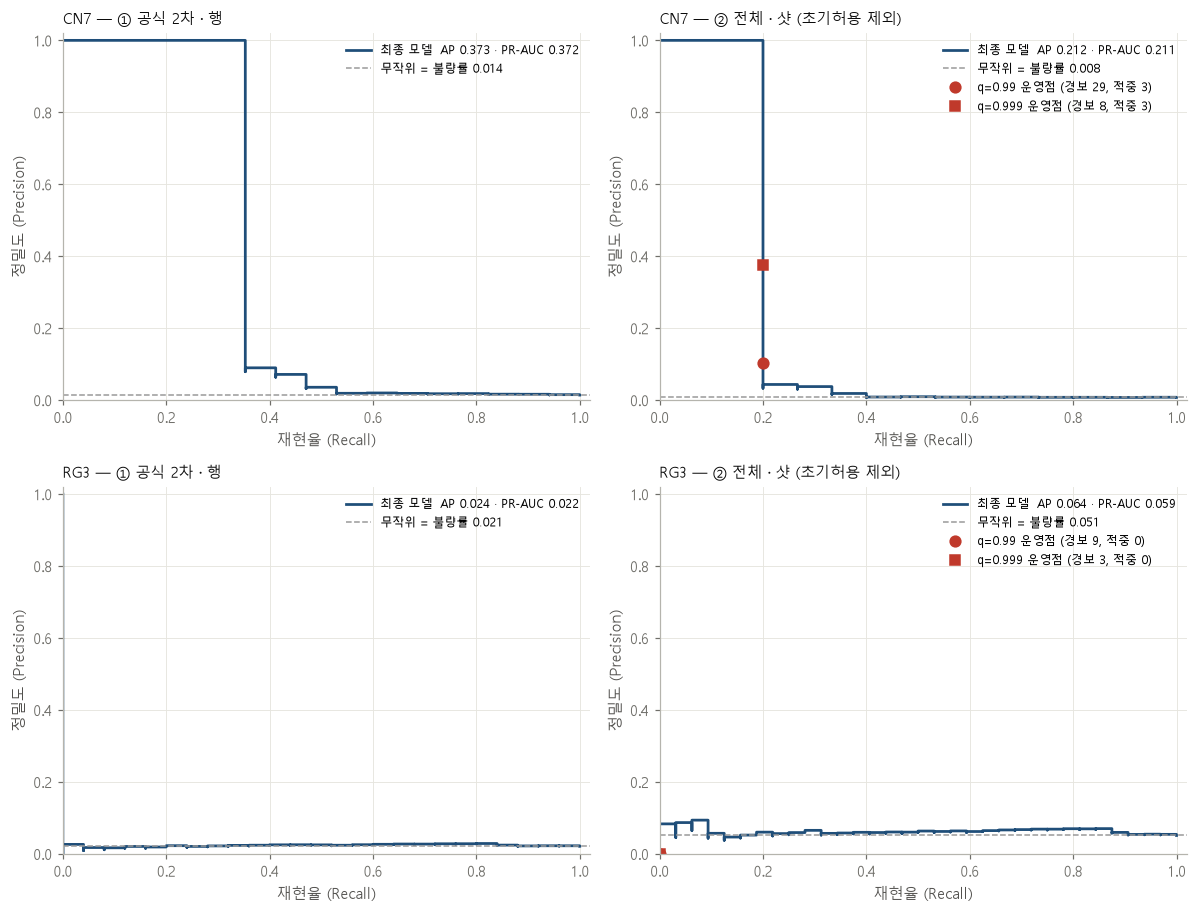

In [3]:
plot_pr(R, save_dir='./outputs/final_model')